<a href="https://colab.research.google.com/github/DrDourado/ME_640_Optimum_Design_Fall_2026/blob/main/ME_640_03_Constrained_Desing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Constrained Optimization

**ME 640 - Optimum Design Methods | Module 2 - Gradient-Based Constrained Design**  
**Format:** guided notebook (read -> predict -> run -> interpret -> extend)

## Learning objectives
- Implement bounds and nonlinear inequality constraints
- Interpret active constraints and multiple starting points
- Verify a solver design through direct substitution

## Responsible AI checkpoint
You may use a generative-AI assistant to explain syntax, propose tests, or critique your interpretation. You remain responsible for the formulation, units, constraints, verification, and final engineering claims. Record any material AI assistance in the reflection cell at the end.

In [ ]:
import numpy as np
from scipy import optimize
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

## Case study: minimum-volume spring

Use the classical three-variable benchmark with wire diameter $d$, mean coil diameter $D$, and active turns $N$. Minimize

$$f=(N+2)Dd^2$$

subject to four normalized inequalities $g_i(x)\le0$ and bounds.

$g_1(x): 1 - \frac{D^3N}{71785d^4} \le 0$

$g_2(x): \frac{4D^2-dD}{12566(Dd^3-d^4)} + \frac{1}{5108d^2} - 1  \le 0$

$g_3(x): 1 - 140.45\frac{d}{D^2N} \le 0$

$g_4(x): \frac{d+D}{1.5} - 1 \le 0$

$ 0.05 \le d \le 2$, $ 0.25 \le D \le 1.3$, $ 2 \le N \le 15$

Variables are dimensionless benchmark units; the exercise emphasizes formulation and verification.


In [ ]:
def obj(x):
    d,D,N=x
    return (N+2)*D*d**2
def g(x):
    d,D,N=x
    return np.array([
        1 - D**3*N/(71785*d**4),
        (4*D**2-d*D)/(12566*(D*d**3-d**4)) + 1/(5108*d**2) - 1,
        1 - 140.45*d/(D**2*N),
        (d+D)/1.5 - 1
    ])
bounds=optimize.Bounds([0.05,0.25,2.0],[2.0,1.3,15.0])
cons={"type":"ineq","fun":lambda x:-g(x)}
x0=np.array([0.10,0.80,8.0])
print("initial objective",obj(x0),"g=",g(x0))

initial objective 0.08000000000000002 g= [ 0.42940726 -0.69848294 -1.74316406 -0.4       ]


### Solving the Optimization Problem

Now we will use `scipy.optimize.minimize` to find the optimal values for $d, D, N$ that minimize the objective function $f=(N+2)Dd^2$ subject to the given constraints and bounds. We'll use the `SLSQP` method, which is suitable for constrained nonlinear optimization problems.

### The SLSQP Method (Sequential Least Squares Programming)
`SLSQP` is a robust and widely used algorithm for solving nonlinear optimization problems with both equality and inequality constraints, as well as bounds on variables.
It works in an iterative fashion:

1. **Quadratic Programming (QP) Subproblems**: In each iteration, SLSQP approximates the original nonlinear optimization problem with a simpler Quadratic Programming (QP) subproblem. This involves:

* Approximating the objective function with a quadratic function.
* Approximating the constraints with linear functions.

2. **Solving the QP**: It then solves this QP subproblem to determine a search direction.

3. **Line Search**: A line search is performed along this direction to find a step size that improves the objective function while maintaining feasibility (or moving towards it). This often involves using a 'merit function' to balance objective improvement and constraint satisfaction.

4. **Updating Approximations**: The approximations (Hessian of the Lagrangian, constraint gradients) are updated for the next iteration.

`SLSQP` is known for its effectiveness on many practical problems, especially when the objective and constraint functions are smooth.
It's a 'sequential' method because it solves a sequence of simpler problems.

### Interpreting the Solution and KKT Conditions

The `scipy.optimize.minimize` output provides details about the optimization process and the final solution.

The KKT conditions are necessary (and sometimes sufficient) conditions for a solution in nonlinear programming to be optimal.
They involve the gradients of the objective and constraint functions, and the Lagrange multipliers.

Key KKT Conditions:
1.  **Stationarity**: The gradient of the Lagrangian (objective + sum of Lagrange multiplier * constraint) with respect to the variables is zero.
($\nabla f(x^*)+∑{λ_i \nabla g_i(x^*)}+∑{λ_j \nabla h_j(x^*)}=0 $)

* **Logic**: At an unconstrained optimum, the gradient of the objective function ($\nabla f(x^*)$) must be zero.
When constraints are present, the optimum might be on a boundary.
In such cases, the gradient of the objective function must be offset by a linear combination of the gradients of the active constraints.
If it weren't, you could move along the constraint boundary to further decrease (for minimization) the objective function.
The Lagrange multipliers ($\lambda_i$ for inequalities, $\lambda_j$ for equalities) represent the 'cost' of the constraint, indicating how sensitive the objective function is to a change in that constraint.

2.  **Primal Feasibility**: All constraints are satisfied at the solution.
($g_i(x^*) \le 0$ and $h_j(x^*) = 0$):

* **Logic**: This simply states that an optimal solution must satisfy all the original constraints of the problem. It must lie within the feasible region.

3.  **Dual Feasibility**: Lagrange multipliers associated with inequality constraints are non-negative.
($\lambda_i \ge 0$):

* **Logic**: For inequality constraints ($g_i(x) \le 0$), the Lagrange multipliers ($\lambda_i$) must be non-negative.
If a $\lambda_i$ were negative, it would imply that relaxing the constraint ($g_i(x) \le \epsilon$ for some $\epsilon > 0$) would increase the objective value for a minimization problem.
This contradicts the idea that the constraint is holding back further improvement, or that you're at a minimum.
So, a positive $\lambda_i$ means the constraint is restricting the objective, while a zero $\lambda_i$ means the constraint isn't limiting the objective at that point.

4.  **Complementary Slackness**: For each inequality constraint, either the constraint is active (equal to zero) or its corresponding Lagrange multiplier is zero. ($\lambda_i g_i(x^*) = 0$):

* **Logic**: This condition links the Lagrange multipliers to the active status of inequality constraints.
It means that for each inequality constraint, either:
The constraint is active ($g_i(x^*) = 0$), in which case its Lagrange multiplier ($\lambda_i$) is positive (meaning the constraint is binding and influencing the optimum).
The constraint is slack ($g_i(x^*) < 0$), in which case its Lagrange multiplier ($\lambda_i$) must be zero (meaning the constraint is not binding and has no influence on the optimum).
This ensures that only active constraints contribute to the 'pull' on the objective function's gradient at the optimum.



In [ ]:
# Define a callback function to record the optimization path
optimization_path = []
def callback_func(xk, *args):
    optimization_path.append(xk.copy())

# Run the optimization
# The 'cons' dictionary was already defined in the previous cell.
# 'ineq' constraints are formulated as g(x) >= 0. Since our g(x) <= 0, we use -g(x) >= 0.
sol = optimize.minimize(
    obj, x0, method='SLSQP', bounds=bounds, constraints=cons, callback=callback_func
)

print("Optimization Result:")
print(sol)

Optimization Result:
     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 0.01281337802370177
           x: [ 5.460e-02  4.309e-01  7.976e+00]
         nit: 7
         jac: [ 4.694e-01  2.974e-02  1.284e-03]
        nfev: 28
        njev: 7
 multipliers: [ 1.112e-02  2.480e-02  0.000e+00  0.000e+00]


In [ ]:
sol.x

array([0.05459926, 0.4308545 , 7.97606939])

In [ ]:
g(sol.x)

array([-1.22380273e-07,  4.14400098e-07, -4.17914791e+00, -6.76364156e-01])

In [ ]:
g(np.array([sol.x[0],sol.x[1],8.0]))

array([-3.00042414e-03,  4.14400098e-07, -4.16365539e+00, -6.76364156e-01])

In [ ]:
obj(sol.x)

np.float64(0.01281337802370177)

In [ ]:
obj(np.array([sol.x[0],sol.x[1],8.0]))

np.float64(0.012844114776578416)

In [ ]:
# Extract optimal values
x_opt = sol.x
f_opt = sol.fun
constraints_at_opt = g(x_opt)

print(f"\nOptimal design variables (d, D, N): {x_opt}")
print(f"Minimum objective function value: {f_opt:.4f}")
print(f"Constraint values at optimum g(x) <= 0: {constraints_at_opt}")

# Lagrange multipliers for constraints are often in sol.v or sol.jac in SLSQP results
# For SLSQP, the Lagrange multipliers for the constraints are available in sol.v
# Note: sol.v contains multipliers for bounds and then for constraints.
# The number of inequality constraints is len(cons['fun'](x_opt)).
# The number of bounds is 2 * len(x_opt).
# So, the multipliers for inequality constraints start after the bound multipliers.

# Let's verify the number of variables and constraints from our problem setup
num_vars = len(x0)
num_ineq_constraints = len(constraints_at_opt)

print(f"\nStatus: {sol.message}")
print(f"Success: {sol.success}")

if sol.success:
    # Lagrange multipliers for the inequality constraints (if available)
    # For SLSQP, `sol.v` contains the multipliers for the bounds first, then for the constraints.
    # The order for bounds is typically lower bounds then upper bounds.
    # The order for constraints matches the order in which they were provided in `cons`.
    # We need to ensure we are accessing the correct part of `sol.v`
    try:
        # sol.v structure: [lower bound multipliers, upper bound multipliers, inequality constraint multipliers]
        # There are `num_vars` lower bounds and `num_vars` upper bounds
        lagrange_multipliers = sol.v[-num_ineq_constraints:]
        print(f"Lagrange multipliers for inequality constraints: {lagrange_multipliers}")

        # Check KKT Complementary Slackness and Dual Feasibility
        print("\n--- KKT Condition Check ---")
        print("1. Primal Feasibility (all g(x) <= 0):")
        for i, val in enumerate(constraints_at_opt):
            print(f"   g_{i+1}(x) = {val:.4e} <= 0 (Satisfied: {val <= 1e-6})") # Using a small tolerance for 'equal to zero'

        print("2. Dual Feasibility (Lagrange multipliers >= 0):")
        for i, lm in enumerate(lagrange_multipliers):
            print(f"   Lambda_{i+1} = {lm:.4e} >= 0 (Satisfied: {lm >= -1e-6})") # Using a small tolerance for 'non-negative'

        print("3. Complementary Slackness (Lambda_i * g_i(x) = 0):")
        for i, (lm, gc) in enumerate(zip(lagrange_multipliers, constraints_at_opt)):
            product = lm * gc
            print(f"   Lambda_{i+1} * g_{i+1}(x) = {lm:.4e} * {gc:.4e} = {product:.4e} (Near zero: {abs(product) < 1e-6})")
            if abs(product) < 1e-6:
                if abs(lm) < 1e-6 and gc < -1e-6: # Lambda is zero, constraint is slack
                    print(f"     Constraint g_{i+1} is slack (g_{i+1} < 0) and Lambda_{i+1} is zero.")
                elif abs(gc) < 1e-6 and lm > 1e-6: # Constraint is active, Lambda is positive
                    print(f"     Constraint g_{i+1} is active (g_{i+1} ~ 0) and Lambda_{i+1} is positive.")
                elif abs(lm) < 1e-6 and abs(gc) < 1e-6: # Both are zero (active and lambda zero, less common)
                    print(f"     Constraint g_{i+1} is active (g_{i+1} ~ 0) and Lambda_{i+1} is zero.")
                else: # Should not happen if KKT holds well
                    print(f"     Unexpected: Lambda_{i+1} * g_{i+1}(x) is near zero but not clearly active/slack.")
            else:
                print(f"     Complementary slackness potentially violated: {product:.4e}")

    except IndexError:
        print("Could not retrieve Lagrange multipliers from `sol.v` or `sol.jac` for this method.")
        print("Some solvers/methods do not directly expose Lagrange multipliers in `sol.v` or `sol.jac` in a straightforward manner.")
        print("For SLSQP, they are usually in `sol.v` but their position might vary based on problem structure.")
        print("You may need to inspect `sol.v` more closely or use a method like `trust-constr` which provides `lagrangian_multipliers` directly.")
    except AttributeError:
        print("The solver result object 'sol' does not have a 'v' attribute, or it's not structured as expected for Lagrange multipliers.")
else:
    print("Optimization did not succeed, so KKT conditions may not apply or be verifiable.")


Optimal design variables (d, D, N): [0.05459926 0.4308545  7.97606939]
Minimum objective function value: 0.0128
Constraint values at optimum g(x) <= 0: [-1.22380273e-07  4.14400098e-07 -4.17914791e+00 -6.76364156e-01]

Status: Optimization terminated successfully
Success: True
The solver result object 'sol' does not have a 'v' attribute, or it's not structured as expected for Lagrange multipliers.


/tmp/ipykernel_640/3814970532.py:8: RuntimeWarning: divide by zero encountered in scalar divide
  (4*D**2-d*D)/(12566*(D*d**3-d**4)) + 1/(5108*d**2) - 1,


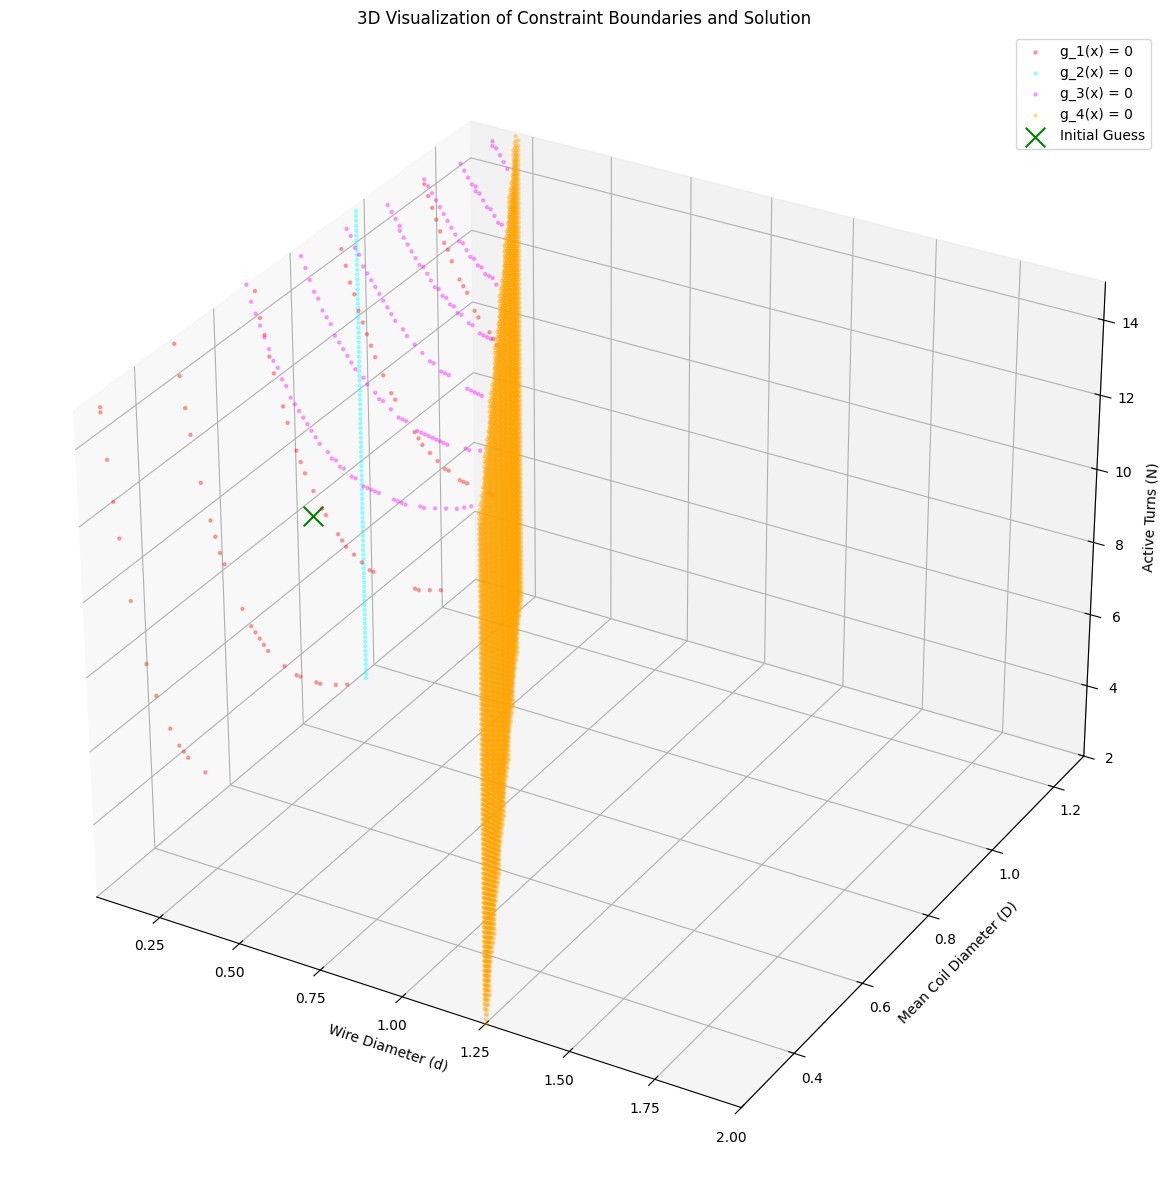

Note: Directly visualizing the objective function as a 'surface' in this 3D plot along with constraint surfaces is complex and often leads to visual clutter in standard matplotlib. This plot focuses on the constraint boundaries. The optimal solution is shown as a red star.


In [ ]:
# Assuming x0, bounds, obj, g are available from previous cells' execution

# Define ranges for d, D, and N based on bounds
d_min, d_max = bounds.lb[0], bounds.ub[0]
D_min, D_max = bounds.lb[1], bounds.ub[1] # Corrected this line
N_min, N_max = bounds.lb[2], bounds.ub[2]

# Create a 3D grid
num_points_per_dim = 100 # Can adjust for density vs. computation time
d_vals = np.linspace(d_min, d_max, num_points_per_dim)
D_vals = np.linspace(D_min, D_max, num_points_per_dim)
N_vals = np.linspace(N_min, N_max, num_points_per_dim)

D_grid, d_grid, N_grid = np.meshgrid(D_vals, d_vals, N_vals, indexing='ij') # Use 'ij' for logical indexing

# Flatten grids to iterate through points
points = np.array([d_grid.ravel(), D_grid.ravel(), N_grid.ravel()]).T

# Storage for points on constraint boundaries
constraint_surface_points = [[] for _ in range(4)]
# Tolerance for considering a constraint 'active' (on the surface)
tolerance = 5e-3 # Increased tolerance for visibility with fewer points

for p in points:
    try:
        g_val = g(p)
        for c_idx in range(4):
            # If constraint value is close to zero, add it to the surface points
            if abs(g_val[c_idx]) < tolerance:
                constraint_surface_points[c_idx].append(p)
    except ZeroDivisionError:
        # Skip points that cause division by zero in constraints
        continue

# Convert lists of points to numpy arrays
for c_idx in range(4):
    constraint_surface_points[c_idx] = np.array(constraint_surface_points[c_idx])

# Create the 3D plot
fig = plt.figure(figsize=(14, 12))
ax = fig.add_subplot(111, projection='3d')

# Plot constraint boundaries as scatter plots
colors = ['red', 'cyan', 'magenta', 'orange']
labels = ['g_1(x) = 0', 'g_2(x) = 0', 'g_3(x) = 0', 'g_4(x) = 0']

for c_idx in range(4):
    if len(constraint_surface_points[c_idx]) > 0:
        ax.scatter(constraint_surface_points[c_idx][:, 0],
                   constraint_surface_points[c_idx][:, 1],
                   constraint_surface_points[c_idx][:, 2],
                   color=colors[c_idx],
                   s=5, # Marker size
                   alpha=0.3, # Transparency
                   label=labels[c_idx])

# Mark the initial guess
ax.scatter(x0[0], x0[1], x0[2], color='g', marker='x', s=200, label='Initial Guess')

# Set axis labels and title
ax.set_xlabel('Wire Diameter (d)')
ax.set_ylabel('Mean Coil Diameter (D)')
ax.set_zlabel('Active Turns (N)')
ax.set_title('3D Visualization of Constraint Boundaries and Solution')
ax.legend()

# Set axis limits
ax.set_xlim(d_min, d_max)
ax.set_ylim(D_min, D_max)
ax.set_zlim(N_min, N_max)

plt.tight_layout()
plt.show()

print("Note: Directly visualizing the objective function as a 'surface' in this 3D plot along with constraint surfaces is complex and often leads to visual clutter in standard matplotlib. This plot focuses on the constraint boundaries. The optimal solution is shown as a red star.")

### Visualizing the Optimization Path

Visualizing the optimization path can provide insight into how the solver navigates the design space to reach the optimum. Since we have three variables ($d, D, N$), a 3D plot is appropriate. We can also plot the change in objective function value over iterations.

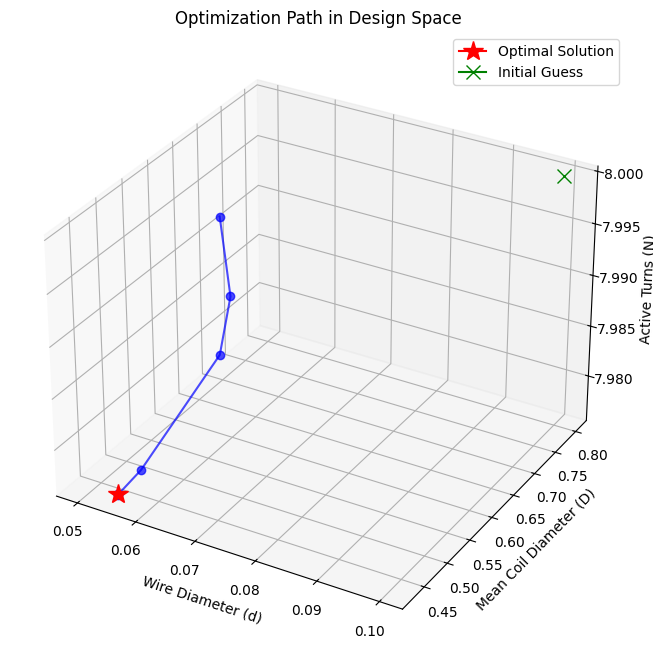

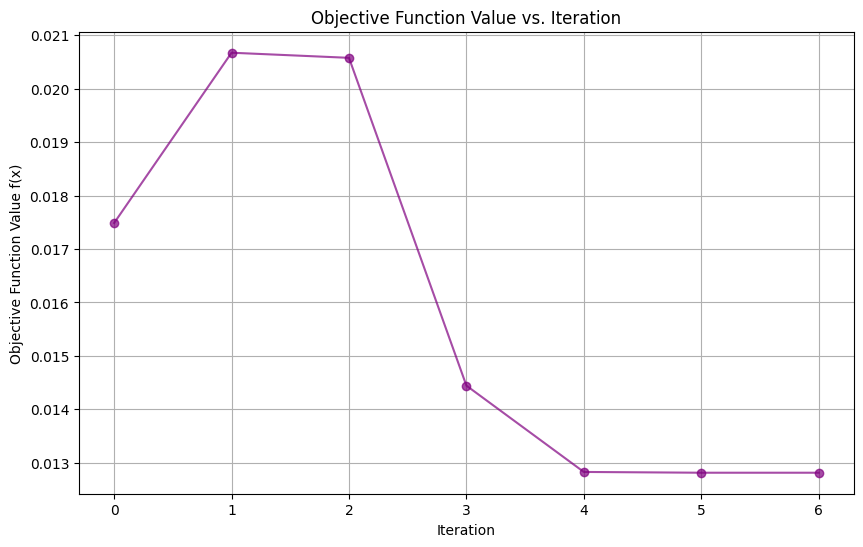

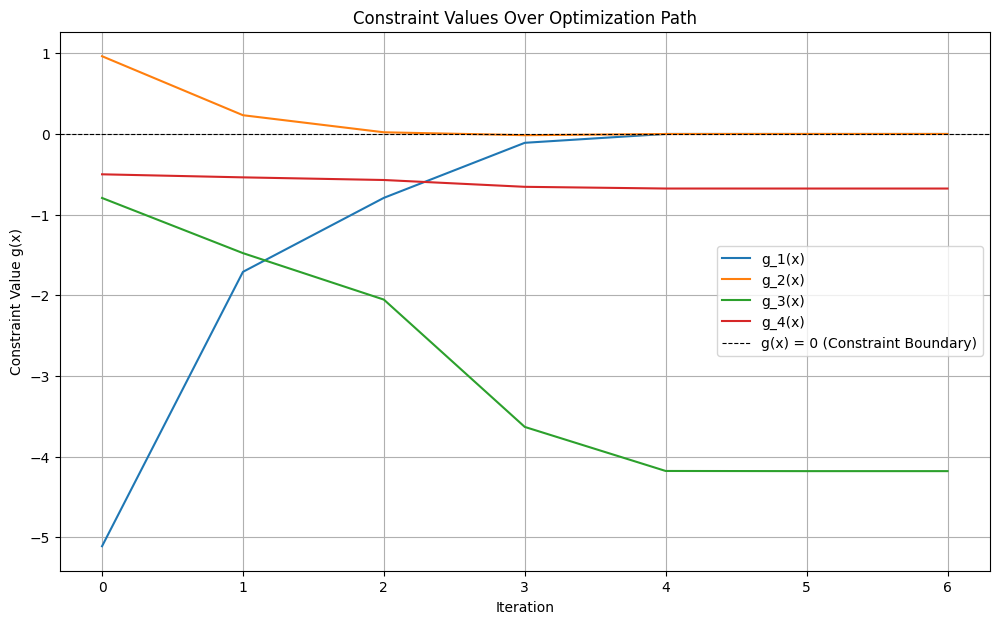

In [ ]:
# Convert optimization_path to a numpy array for easier plotting
path_array = np.array(optimization_path)

if path_array.shape[0] > 0:
    d_path = path_array[:, 0]
    D_path = path_array[:, 1]
    N_path = path_array[:, 2]

    # Plot 1: 3D optimization path in variable space
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    ax.plot(d_path, D_path, N_path, marker='o', linestyle='-', color='b', alpha=0.7)
    ax.plot([x_opt[0]], [x_opt[1]], [x_opt[2]], marker='*', markersize=15, color='r', label='Optimal Solution')
    ax.plot([x0[0]], [x0[1]], [x0[2]], marker='x', markersize=10, color='g', label='Initial Guess')

    ax.set_xlabel('Wire Diameter (d)')
    ax.set_ylabel('Mean Coil Diameter (D)')
    ax.set_zlabel('Active Turns (N)')
    ax.set_title('Optimization Path in Design Space')
    ax.legend()
    plt.grid(True)
    plt.show()

    # Plot 2: Objective function value along the path
    obj_path_values = [obj(point) for point in optimization_path]

    fig2, ax2 = plt.subplots(figsize=(10, 6))
    ax2.plot(range(len(obj_path_values)), obj_path_values, marker='o', linestyle='-', color='purple', alpha=0.7)
    ax2.set_xlabel('Iteration')
    ax2.set_ylabel('Objective Function Value f(x)')
    ax2.set_title('Objective Function Value vs. Iteration')
    ax2.grid(True)
    plt.show()

    # Plot 3: Constraints over iterations
    fig3, ax3 = plt.subplots(figsize=(12, 7))
    constraints_over_path = np.array([g(point) for point in optimization_path])

    for i in range(constraints_over_path.shape[1]):
        ax3.plot(constraints_over_path[:, i], label=f'g_{i+1}(x)')

    ax3.axhline(0, color='black', linestyle='--', linewidth=0.8, label='g(x) = 0 (Constraint Boundary)')
    ax3.set_xlabel('Iteration')
    ax3.set_ylabel('Constraint Value g(x)')
    ax3.set_title('Constraint Values Over Optimization Path')
    ax3.legend()
    ax3.grid(True)
    plt.show()

else:
    print("Optimization path is empty. Callback might not have been called or no iterations occurred.")

## Lecture Notes Example:

Minimize:

$$f(x)=(x_1-10)^3+(x_2-20)^3$$

subject to:

$$g_1(x): 100 - (x_1-5)^2 - (x_2-5)^2 \le 0$$

$$g_2(x): -82.81 - (x_1-6)^2 - (x_2-5)^2 \le 0$$

$ 13 \le x_1 \le 100$, and $ 0 \le x_2 \le 100$


In [ ]:
def lecture_obj(x):
    x1,x2=x
    return (x1-10.0)**3 + (x2-20.0)**3
def lecture_g(x):
    x1,x2=x
    return np.array([
        100-(x1-5)**2 - (x2-5)**2,
        -82.81-(x1-6)**2 - (x2-5)**2
    ])
lecture_bounds=optimize.Bounds([13,0],[100,100])
lecture_cons={"type":"ineq","fun":lambda x:-lecture_g(x)}
lecture_x0=np.array([25,25])
print("initial objective",lecture_obj(lecture_x0),"g=",lecture_g(lecture_x0))

initial objective 3500.0 g= [-700.   -843.81]


In [ ]:
# Define a callback function to record the optimization path
optimization_path = []
def callback_func(xk, *args):
    optimization_path.append(xk.copy())

# Run the optimization
# The 'cons' dictionary was already defined in the previous cell.
# 'ineq' constraints are formulated as g(x) >= 0. Since our g(x) <= 0, we use -g(x) >= 0.
lecture_sol = optimize.minimize(
    lecture_obj, lecture_x0, method='SLSQP', bounds=lecture_bounds, constraints=lecture_cons, callback=callback_func
)

print("Optimization Result:")
print(lecture_sol)

Optimization Result:
     message: Optimization terminated successfully
     success: True
      status: 0
         fun: -7950.961894495045
           x: [ 1.366e+01  0.000e+00]
         nit: 16
         jac: [ 4.019e+01  1.200e+03]
        nfev: 36
        njev: 12
 multipliers: [ 2.321e+00  0.000e+00]


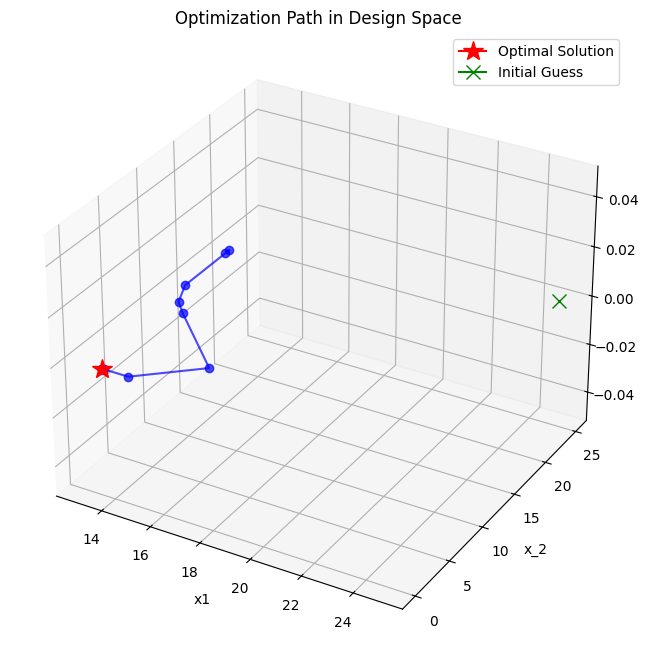

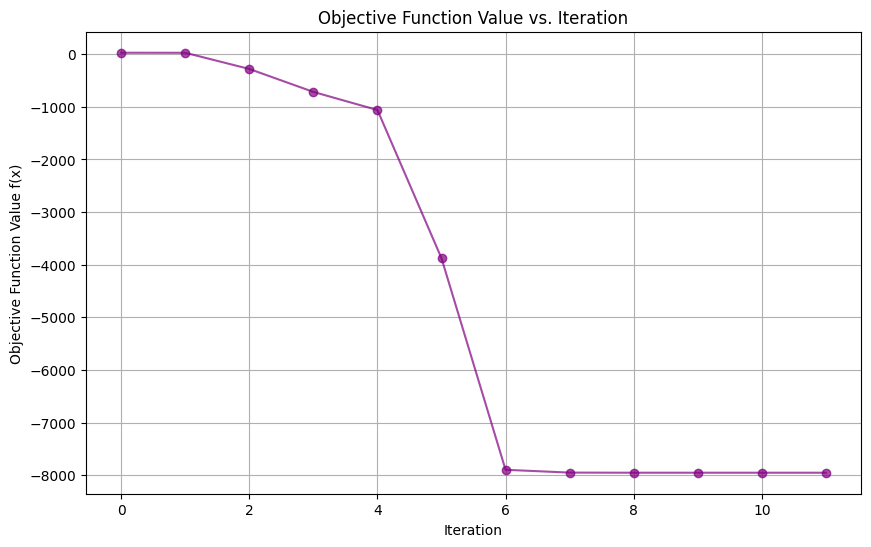

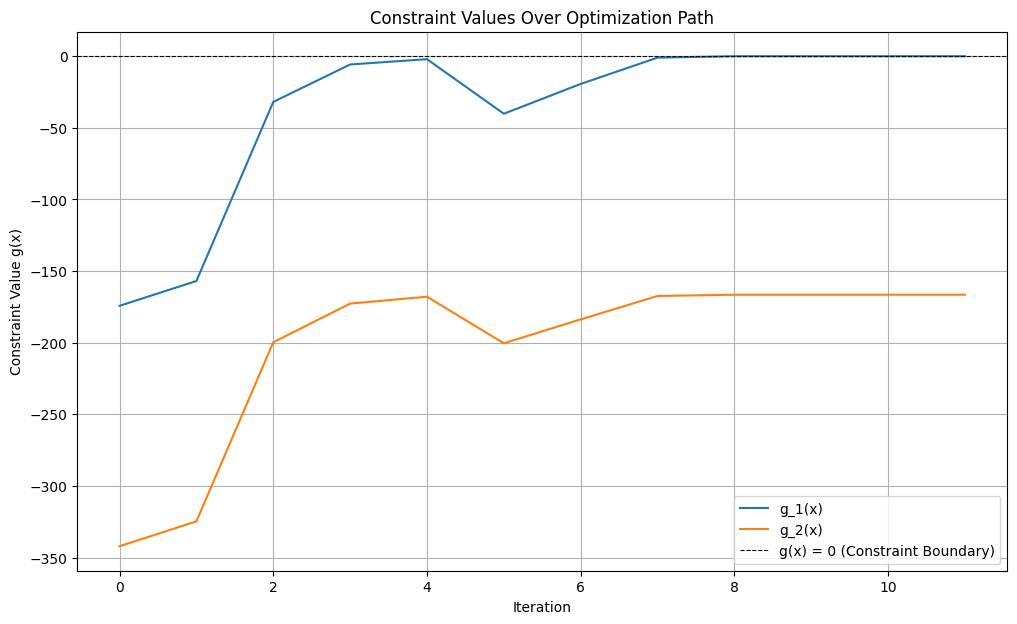

In [ ]:
# Convert optimization_path to a numpy array for easier plotting
path_array = np.array(optimization_path)
lecture_opt = lecture_sol.x

if path_array.shape[0] > 0:
    x1_path = path_array[:, 0]
    x2_path = path_array[:, 1]

    # Plot 1: 3D optimization path in variable space
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    ax.plot(x1_path, x2_path, marker='o', linestyle='-', color='b', alpha=0.7)
    ax.plot([lecture_opt[0]], [lecture_opt[1]], marker='*', markersize=15, color='r', label='Optimal Solution')
    ax.plot([lecture_x0[0]], [lecture_x0[1]], marker='x', markersize=10, color='g', label='Initial Guess')

    ax.set_xlabel('x1')
    ax.set_ylabel('x_2')
    ax.set_title('Optimization Path in Design Space')
    ax.legend()
    plt.grid(True)
    plt.show()

    # Plot 2: Objective function value along the path
    obj_path_values = [lecture_obj(point) for point in optimization_path]

    fig2, ax2 = plt.subplots(figsize=(10, 6))
    ax2.plot(range(len(obj_path_values)), obj_path_values, marker='o', linestyle='-', color='purple', alpha=0.7)
    ax2.set_xlabel('Iteration')
    ax2.set_ylabel('Objective Function Value f(x)')
    ax2.set_title('Objective Function Value vs. Iteration')
    ax2.grid(True)
    plt.show()

    # Plot 3: Constraints over iterations
    fig3, ax3 = plt.subplots(figsize=(12, 7))
    constraints_over_path = np.array([lecture_g(point) for point in optimization_path])

    for i in range(constraints_over_path.shape[1]):
        ax3.plot(constraints_over_path[:, i], label=f'g_{i+1}(x)')

    ax3.axhline(0, color='black', linestyle='--', linewidth=0.8, label='g(x) = 0 (Constraint Boundary)')
    ax3.set_xlabel('Iteration')
    ax3.set_ylabel('Constraint Value g(x)')
    ax3.set_title('Constraint Values Over Optimization Path')
    ax3.legend()
    ax3.grid(True)
    plt.show()

else:
    print("Optimization path is empty. Callback might not have been called or no iterations occurred.")

## Now is your turn:

Minimize:

$$f(R,t)=78500\pi Rt$$

subject to:

$$g_1(R,t): \frac{100000}{2\pi Rt}[1+(\frac{0.02R(R+0.5t)(2\pi Rt)}{\pi R^3t})\frac{1}{\cos(\frac{5}{\sqrt(\frac{\pi R^3 t}{2\pi Rt}(\sqrt{\frac{100000}{210*10^9 2\pi Rt}}))})}] -250*10^6\le 0$$

$$g_2(R,t): 100000 - \pi^2\frac{210*10^9 \pi R^3t}{100}  \le 0$$

$$g_3(R,t): 0.02R[\frac{1}{\cos(5\sqrt{\frac{100000}{210*10^9 \pi R^3t}})}-1] -0.25\le 0$$

$$g_4(R,t): \frac{R}{t}-50 \le 0$$

$ 0.01 \le R \le 1$, and $ 0.005 \le t \le 0.2$
